# 03 – Baseline Models

This notebook sets the **baseline**: train three standard classifiers on the 165 raw features, each with and without class weighting, compared on the time-based folds of `02_validation_setup.ipynb`. The best one becomes the **first Kaggle submission** and the reference point that every later idea (graph features, tuning, ensembling) must beat on the same folds.

## Models compared
| Model | How it works | Why it is included |
|---|---|---|
| Logistic regression | Linear model on standardised features | Interpretable linear reference; shows how much the non-linear models gain |
| Random forest | Bagged decision trees on random subsets of rows and features | Robust to correlated, heavy-tailed features; a strong classic baseline on Elliptic data |
| LightGBM | Gradient boosting: each new tree is fitted to the errors of the trees before it | Usually the strongest learner on tabular data |

**Class weighting.** Each model is tried with and without `class_weight="balanced"`. Only 11.7% of labeled transactions are illicit, so without weighting the licit majority dominates the loss.
The balanced setting up-weights each illicit row so that both classes carry equal total weight.

## 0. Setup
Model definitions live in `src/models.py` and the validation folds in `src/validation.py`, so later notebooks reuse exactly the same code.

**Helpers**
- `make_logreg`, `make_random_forest`, `make_lightgbm`: build a new, untrained model; `balanced=True` switches on class weighting.
- `evaluate(make_model, df, features, folds)`: trains a fresh model on each fold and returns the AUC per fold.
- `log_experiment(name, results, notes)`: saves one model's fold AUCs in `experiments.csv` (re-running a model replaces its old row).
- `save_submission(test, probabilities, filename)`: writes a Kaggle CSV (`index,target`) to `submissions/`.

In [1]:
import sys
sys.path.append("..")  # add the repo root so `src` can be imported from inside notebooks/

import matplotlib.pyplot as plt
import pandas as pd

from src.data import load_train, load_test, labeled, save_submission, FEATURE_COLS, LABEL_COL
from src.models import make_logreg, make_random_forest, make_lightgbm
from src.validation import FOLDS, LATE_FOLDS, evaluate, log_experiment

pd.set_option("display.width", 150)  # print wide tables on one line

## 1. Load data
The labeled training rows (to fit and validate) and the test rows (to predict).

In [2]:
lab = labeled(load_train())  # labeled training rows (time steps 1-35)
test = load_test()           # rows to predict (time steps 36-49)
print(f"Labeled training rows: {len(lab):,} | test rows: {len(test):,}")

Labeled training rows: 31,235 | test rows: 15,329


## 2. Compare models on the time-based folds
Each model is evaluated on both fold sets from `02_validation_setup.ipynb`, with a fresh model for every fold:
- the 4 **late folds** (validate on steps 25-35, 27-35, 29-35, 31-35): their **mean AUC** decides which model is better;
- the 3 **early folds** (validate on steps 21-25, 26-30, 31-35): a second view, whose first fold shows how a model copes with the new illicit pattern of step 24.

Strong models score close to 1.0 on the late folds, so their mean AUC is printed with 5 decimals. Every result is logged in `experiments.csv`.
The six candidates are trained 7 times each (4 late + 3 early folds), 42 fits in all.

In [3]:
# name -> function that builds a fresh, untrained model
candidates = {
    "Logistic regression":            lambda: make_logreg(),
    "Logistic regression (balanced)": lambda: make_logreg(balanced=True),
    "Random forest":                  lambda: make_random_forest(),
    "Random forest (balanced)":       lambda: make_random_forest(balanced=True),
    "LightGBM":                       lambda: make_lightgbm(),
    "LightGBM (balanced)":            lambda: make_lightgbm(balanced=True),
}

late_results, early_results = {}, {}
for name, make_model in candidates.items():
    late_results[name] = evaluate(make_model, lab, FEATURE_COLS, folds=LATE_FOLDS)
    early_results[name] = evaluate(make_model, lab, FEATURE_COLS, folds=FOLDS)
    # keep a record of both in experiments.csv
    log_experiment(name, late_results[name], notes="baseline, 165 raw features")
    log_experiment(name, early_results[name], notes="baseline, 165 raw features")
    print(f"{name:32s} late folds: {late_results[name]['auc'].mean():.5f} | early folds: {early_results[name]['auc'].mean():.5f}")

Logistic regression              late folds: 0.90525 | early folds: 0.91931
Logistic regression (balanced)   late folds: 0.89875 | early folds: 0.91522
Random forest                    late folds: 0.99563 | early folds: 0.95290
Random forest (balanced)         late folds: 0.99646 | early folds: 0.97262
LightGBM                         late folds: 0.99771 | early folds: 0.97931
LightGBM (balanced)              late folds: 0.99776 | early folds: 0.98107


One table per fold set: one row per model, one column per fold (named by its validation steps), plus the mean and the worst fold. The late folds first, because they decide.

**Helper:** `summary_table(results)` turns the per-fold results of all mdoels into that table, sorted by mean AUC.

In [5]:
def summary_table(results: dict) -> pd.DataFrame:
    """One row per model, one column per fold, plus the mean AUC and the worst-fold AUC."""
    per_fold = pd.concat(results, names=["model"]).reset_index(level=0)
    table = per_fold.pivot(index="model", columns="valid_steps", values="auc").add_prefix("fold ")
    table["mean AUC"] = table.mean(axis=1)
    table["worst fold"] = table.drop(columns="mean AUC").min(axis=1)
    return table.sort_values("mean AUC", ascending=False)

late_summary = summary_table(late_results)
late_summary.round(5)

valid_steps,fold 25-35,fold 27-35,fold 29-35,fold 31-35,mean AUC,worst fold
model,,,,,,
LightGBM (balanced),0.99718,0.99785,0.99742,0.99857,0.99776,0.99718
LightGBM,0.99735,0.99768,0.99733,0.99849,0.99771,0.99733
Random forest (balanced),0.99602,0.99580,0.99618,0.99784,0.99646,0.99580
Random forest,0.99548,0.99499,0.99506,0.99698,0.99563,0.99499
Logistic regression,0.88637,0.90266,0.90313,0.92884,0.90525,0.88637
Logistic regression (balanced),0.88556,0.89486,0.89696,0.91762,0.89875,0.88556


The early folds, as a second view. The plot shows how each model's AUC changes from one early fold to the next.

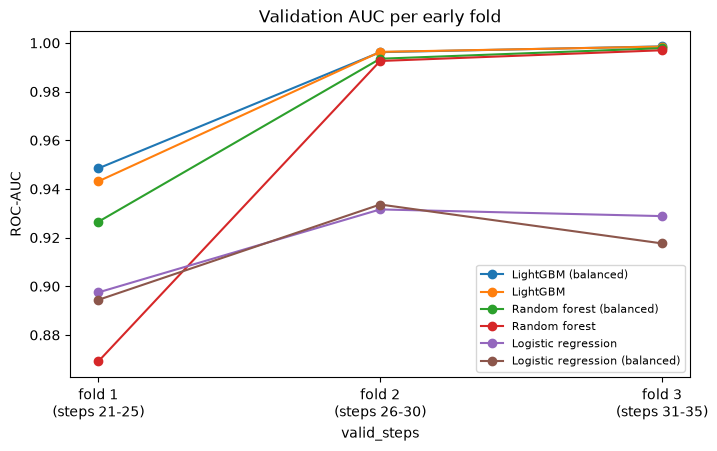

valid_steps,fold 21-25,fold 26-30,fold 31-35,mean AUC,worst fold
model,,,,,
LightGBM (balanced),0.9485,0.9962,0.9986,0.9811,0.9485
LightGBM,0.9431,0.9963,0.9985,0.9793,0.9431
Random forest (balanced),0.9265,0.9935,0.9978,0.9726,0.9265
Random forest,0.8691,0.9926,0.9970,0.9529,0.8691
Logistic regression,0.8975,0.9316,0.9288,0.9193,0.8975
Logistic regression (balanced),0.8944,0.9336,0.9176,0.9152,0.8944


In [6]:
early_summary = summary_table(early_results)

# AUC of each model on each early validation period
early_summary.drop(columns=["mean AUC", "worst fold"]).T.plot(marker="o", figsize=(8, 4.5))
plt.xticks([0, 1, 2], ["fold 1\n(steps 21-25)", "fold 2\n(steps 26-30)", "fold 3\n(steps 31-35)"])
plt.ylabel("ROC-AUC")
plt.title("Validation AUC per early fold")
plt.legend(fontsize=8, loc="lower right")
plt.show()

early_summary.round(4)

**Takeaway:**
- **LightGBM (balanced)** is the best model on both fold sets. With and without class weighting, it ties on the late folds (0.99776 vs 0.99771), and the balanced version is slightly ahead on the early folds (0.9811 vs 0.9793). I keep **LightGBM (balanced)** as the baseline of choice.
- **Class weighting mainly helps with the step-24 change.** On early fold 1, it lifts the random forst from 0.8691 to 0.9265 and LightGBM from 0.9431 to 0.9485. On the late folds, where step 24 is always in training, it barely changes LightGBM. Notebook 05 comes back to this: the final model drops class weighting.
- Logistic regression trails clearly on both fold sets (about 0.90 on the late folds), so the relationship between the features and the label is strongly non-linear.

## 3. Which features does the best model rely on?
LightGBM's **gain importance** measures how much each feature improved the model's splits in total. 
It shows whether the model depends on a handful of features, which would make it fragile if those features drift in the test period.

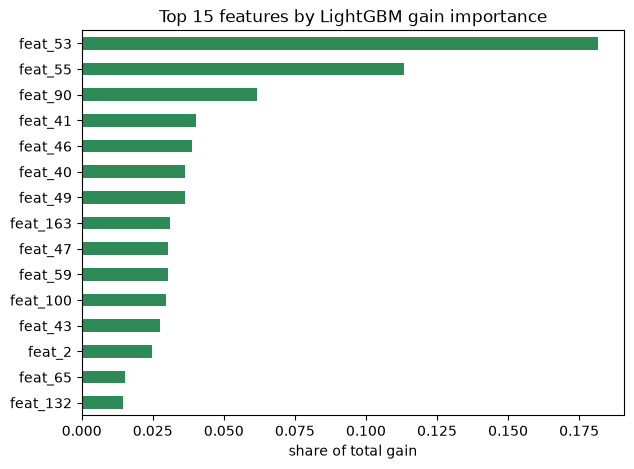

Top 15 features account for 71% of the total gain


In [7]:
best_model = make_lightgbm(balanced=True)
best_model.fit(lab[FEATURE_COLS], lab[LABEL_COL])  # train on ALL labeled data (time steps 1-35)

importance = pd.Series(best_model.booster_.feature_importance(importance_type="gain"), index=FEATURE_COLS)
importance = importance / importance.sum()  # share of total gain, easier to read

importance.sort_values().tail(15).plot.barh(figsize=(7, 5), color="seagreen",
                                            title="Top 15 features by LightGBM gain importance")
plt.xlabel("share of total gain")
plt.show()

print(f"Top 15 features account for {importance.nlargest(15).sum():.0%} of the total gain")

**Takeaway:** The 15 most important features carry 71% of the total gain, so the model draws on many features rather than a handful. That makes it less fragile if one feature shifts in the test period (`01_eda.ipynb` found 21 features that shift by more than 0.5 standard deviations).

## 4. First Kaggle submission
The model is retrained on **all** labeled data (time steps 1–35), the data closest to the test period, and predicts the probability that each test transaction is illicit.
Two checks run before the file is saved: one probability per test row, and every probability between 0 and 1.

In [8]:
test_probs = best_model.predict_proba(test[FEATURE_COLS])[:, 1]  # column 1 = probability of illicit

# Sanity checks before uploading: one probability per test row, all between 0 and 1
assert len(test_probs) == len(test)
assert ((test_probs >= 0) & (test_probs <= 1)).all()

path = save_submission(test, test_probs, "03_lightgbm_balanced.csv")
print("Saved:", path.name)
print(f"Mean predicted probability of illicit: {test_probs.mean():.3f}")
pd.read_csv(path).head()

Saved: 03_lightgbm_balanced.csv
Mean predicted probability of illicit: 0.045


,index,target
0,0,0.000105
1,1,0.001518
2,2,0.000353
3,3,0.000187
4,4,0.000097


I also submit the second-best model family, the balanced random forest. Two leaderboard scores show whether the leaderboard ranks the models in the same order as my folds.

In [9]:
forest = make_random_forest(balanced=True)
forest.fit(lab[FEATURE_COLS], lab[LABEL_COL])  # train on ALL labeled data (time steps 1-35)
forest_probs = forest.predict_proba(test[FEATURE_COLS])[:, 1]

path = save_submission(test, forest_probs, "03_random_forest_balanced.csv")
print("Saved:", path.name)

Saved: 03_random_forest_balanced.csv


### Leaderboard results
Both files were uploaded to Kaggle (the random forest file under the name `probe_random_forest_balanced.csv`). Public leaderboard scores:

| Submission | Late folds (mean AUC) | Early folds (mean AUC) | Public leaderboard |
|---|---|---|---|
| `03_lightgbm_balanced.csv` | 0.99776 | 0.9811 | **0.94637** |
| `03_random_forest_balanced.csv` | 0.99646 | 0.9726 | 0.93650 |

**Takeaway:** The leaderboard ranks the two models in the same order as both fold sets. But the leaderboard score is far below every validation score (0.946 vs 0.998 on the late folds): the test period differs from the training period more than any of my folds can show. Closing that gap is the aim of the next notebooks.

## 5. Summary
| Result | Detail |
|---|---|
| Best baseline | LightGBM with class weighting: 0.99776 on the late folds, 0.94637 on the public leaderboard |
| Effect of class weighting | Large on early fold 1 (the step 24 change), almost none for LightGBM on the late folds |
| Validation vs Leaderboard | Same ranking of the two submitted models, but the leaderboard score is much lower (0.946 vs 0.998) |
| Submissions | `submissions/03_lightgbm_balanced.csv` (0.94637), `submissions/03_random_forest_balanced.csv` (0.93650) |

**Next:** `04_graph_features.ipynb` adds features built from the transaction graph (the EDA showed illicit transactions cluster together) and checks whether they beat this baseline on the same folds.